# Análise exploratória de dados — CAT no Ceará

O notebook investiga os registros de **Comunicação de Acidente de Trabalho (CAT)** com **UF do acidente registrada como Ceará** e data de ocorrência no **primeiro semestre de 2026**. Cada linha é um registro disponível nos arquivos. Uma pessoa ou ocorrência pode aparecer em mais de um registro.

## Objetivos

1. Descrever o perfil por sexo e faixa etária.
2. Identificar as atividades e os setores econômicos com mais registros.
3. Comparar os tipos de acidente disponíveis.
4. Verificar se a base permite comparar municípios onde ocorreram os acidentes.
5. Medir o intervalo entre o acidente e a emissão da CAT.
6. Comparar as contagens por mês do acidente, de janeiro a junho.
7. Identificar quais setores econômicos e tipos de acidente concentram os registros com óbito e compará-los ao volume geral de CATs.

Os resultados e gráficos usam as **7.201 linhas distintas nos 27 campos originais**. A contagem com repetições aparece na auditoria da base e na tabela que mede o efeito das repetições por mês. Para reproduzir, abra o notebook com a raiz do projeto como diretório de trabalho e execute as células em ordem com Python, pandas, Matplotlib e Jupyter.

## 1. Base e preparação

Os seis arquivos mensais estão em `datasets/CAT_2026/`. A leitura usa ponto e vírgula e codificação Latin-1. Os campos com cabeçalhos repetidos ganham nomes únicos conforme sua posição. Cada linha conserva o arquivo de origem e sua posição nele.

A data de extração dos arquivos locais é desconhecida. A análise exibe resultados agregados.

[Catálogo de dados abertos do INSS](https://dadosabertos.inss.gov.br/dataset/comunicacoes-de-acidente-de-trabalho-cat-plano-de-dados-abertos-jun-2023-a-dez-2027)

In [1]:
import csv
import re
import unicodedata
from pathlib import Path
from textwrap import fill

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from matplotlib.ticker import MaxNLocator, PercentFormatter

pasta = Path("datasets")
arquivos = [pasta / "CAT_2026" / f"D.SDA.PDA.005.CAT.2026{mes:02}.csv" for mes in range(1, 7)]
inicio, fim = pd.Timestamp("2026-01-01"), pd.Timestamp("2026-06-30")
pd.set_option("display.max_colwidth", None)


plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "figure.dpi": 120,
})

mkdir -p failed for path /home/aristotelesfl/.config/matplotlib: [Errno 30] Read-only file system: '/home/aristotelesfl/.config/matplotlib'


Matplotlib created a temporary cache directory at /tmp/matplotlib-4y4uq_k8 because there was an issue with the default path (/home/aristotelesfl/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


In [2]:
campos = [
    "agente", "data_acidente", "cbo", "cbo_descricao", "cid", "cid_descricao",
    "cnae", "cnae_descricao", "emitente", "especie_beneficio", "filiacao", "obito",
    "municipio_empregador", "natureza_lesao", "origem_cadastro", "parte_atingida",
    "sexo", "tipo", "uf_acidente", "uf_empregador", "data_afastamento",
    "data_despacho", "data_acidente_2", "data_nascimento", "data_emissao",
    "tipo_empregador", "cnpj_cei",
]
cabecalho_esperado = (
    "Agente Causador Acidente;Data Acidente;CBO;CBO;CID-10;CID-10;"
    "CNAE2.0 Empregador;CNAE2.0 Empregador;Emitente CAT;Espécie do benefício;"
    "Filiação Segurado;Indica Óbito Acidente;Munic Empr;Natureza da Lesão;"
    "Origem de Cadastramento CAT;Parte Corpo Atingida;Sexo;Tipo do Acidente;"
    "UF Munic. Acidente;UF Munic. Empregador;Data Afastamento;Data Despacho Benefício;"
    "Data Acidente;Data Nascimento;Data Emissão CAT;Tipo de Empregador;CNPJ/CEI Empregador"
).split(";")

partes = []
for caminho in arquivos:
    with caminho.open(encoding="latin-1", newline="") as entrada:
        cabecalho = next(csv.reader(entrada, delimiter=";"))
    if [" ".join(nome.split()) for nome in cabecalho] != cabecalho_esperado:
        raise ValueError(f"Esquema inesperado em {caminho.name}.")
    dados = pd.read_csv(caminho, sep=";", encoding="latin-1", dtype=str,
                        keep_default_na=False, header=0, names=campos, skip_blank_lines=False)
    dados["arquivo_origem"] = caminho.name
    dados["linha_origem"] = range(2, len(dados) + 2)
    partes.append(dados)

brutos = pd.concat(partes, ignore_index=True)
del dados, partes
assert not brutos.duplicated(["arquivo_origem", "linha_origem"]).any()
por_arquivo = brutos.groupby("arquivo_origem", sort=True)
inventario = por_arquivo.size().to_frame("Linhas")
inventario["Campos de origem"] = len(campos)
inventario.loc["Total"] = [len(brutos), len(campos)]
display(inventario)

,Linhas,Campos de origem
arquivo_origem,,
D.SDA.PDA.005.CAT.202601.csv,53595,27
D.SDA.PDA.005.CAT.202602.csv,65622,27
D.SDA.PDA.005.CAT.202603.csv,72021,27
D.SDA.PDA.005.CAT.202604.csv,74363,27
D.SDA.PDA.005.CAT.202605.csv,214049,27
D.SDA.PDA.005.CAT.202606.csv,140513,27
Total,620163,27


### Esquema, marcadores e datas

A auditoria distingue valores vazios, `{ñ class}`, datas zeradas e outros marcadores por campo. A data do acidente, a data de emissão e o mês no nome do arquivo são examinados separadamente. As duas colunas de data do acidente são conferidas antes de definir o recorte pela primeira delas.

In [3]:
marcadores = {
    "cbo": ["000000"], "cnae": ["0000"], "municipio_empregador": ["000000-ignorado"],
    "uf_empregador": ["zerado"], "uf_acidente": ["zerado"],
    "sexo": ["indeterminado", "não informado"],
}

def perfil_campos(dados):
    linhas = []
    for campo in campos:
        texto = dados[campo].str.strip().str.lower()
        linhas.append({
            "Campo": campo, "Valores distintos": texto.nunique(), "Vazio": texto.eq("").sum(),
            "{ñ class}": texto.eq("{ñ class}").sum(), "00/00/0000": texto.eq("00/00/0000").sum(),
            "Outro marcador": texto.isin(marcadores.get(campo, [])).sum(),
        })
    return pd.DataFrame(linhas).set_index("Campo")

perfil = perfil_campos(brutos)
esquema = perfil.copy()
esquema.insert(0, "Cabeçalho original", cabecalho)
esquema.insert(0, "Posição", range(1, len(campos) + 1))
esquema.insert(2, "Tipo lido", brutos[campos].dtypes.astype(str))
display(esquema)

,Posição,Cabeçalho original,Tipo lido,Valores distintos,Vazio,{ñ class},00/00/0000,Outro marcador
Campo,,,,,,,,
agente,1,Agente Causador Acidente,str,274,0,3903,0,0
data_acidente,2,Data Acidente,str,213,0,0,0,0
cbo,3,CBO,str,2152,0,0,0,9
cbo_descricao,4,CBO,str,1859,0,81983,0,0
cid,5,CID-10,str,4565,27,0,0,0
cid_descricao,6,CID-10,str,4539,0,1729,0,0
cnae,7,CNAE2.0 Empregador,str,679,0,0,0,21715
cnae_descricao,8,CNAE2.0 Empregador,str,395,0,22025,0,0
emitente,9,Emitente CAT,str,6,0,1055,0,0


In [4]:
def ler_data(serie):
    return pd.to_datetime(serie.str.strip(), format="%d/%m/%Y", errors="coerce")

acidente = ler_data(brutos["data_acidente"])
emissao = ler_data(brutos["data_emissao"])
mes_arquivo = brutos["arquivo_origem"].str[-10:-4]
mes_acidente = acidente.dt.strftime("%Y%m")
mes_emissao = emissao.dt.strftime("%Y%m")
datas = pd.DataFrame({
    "arquivo": brutos["arquivo_origem"], "acidente": acidente, "emissão": emissao,
    "datas de acidente diferentes (texto)": brutos["data_acidente"].ne(brutos["data_acidente_2"]),
    "acidente inválido": acidente.isna(), "emissão inválida": emissao.isna(),
    "acidente fora do mês do arquivo": acidente.notna() & mes_acidente.ne(mes_arquivo),
    "emissão fora do mês do arquivo": emissao.notna() & mes_emissao.ne(mes_arquivo),
    "emissão em outro mês que o acidente": acidente.notna() & emissao.notna() & mes_acidente.ne(mes_emissao),
})
por_origem = datas.groupby("arquivo")
display(por_origem[["acidente", "emissão"]].agg(["min", "max"]))
display(por_origem[datas.columns[3:]].sum())

acidente               emissão           
                                    min        max        min        max
arquivo                                                                 
D.SDA.PDA.005.CAT.202601.csv 2026-01-01 2026-01-31 2026-01-01 2026-02-01
D.SDA.PDA.005.CAT.202602.csv 2026-01-01 2026-03-01 2026-02-01 2026-03-01
D.SDA.PDA.005.CAT.202603.csv 2026-01-01 2026-04-01 2026-03-01 2026-04-01
D.SDA.PDA.005.CAT.202604.csv 2026-01-01 2026-05-01 2026-04-01 2026-05-02
D.SDA.PDA.005.CAT.202605.csv 2026-01-01 2026-08-01 2026-05-01 2026-08-01
D.SDA.PDA.005.CAT.202606.csv 2026-01-01 2026-08-01 2026-06-01 2026-08-01

,datas de acidente diferentes (texto),acidente inválido,emissão inválida,acidente fora do mês do arquivo,emissão fora do mês do arquivo,emissão em outro mês que o acidente
arquivo,,,,,,
D.SDA.PDA.005.CAT.202601.csv,0,0,0,0,17,17
D.SDA.PDA.005.CAT.202602.csv,0,0,0,12451,18,12460
D.SDA.PDA.005.CAT.202603.csv,0,0,0,14840,160,14939
D.SDA.PDA.005.CAT.202604.csv,0,0,0,15569,270,15801
D.SDA.PDA.005.CAT.202605.csv,0,0,0,139963,140513,47111
D.SDA.PDA.005.CAT.202606.csv,0,0,0,69434,65528,32519


### Recorte e linhas repetidas

O recorte seleciona acidentes com UF registrada como Ceará e data entre **1º de janeiro e 30 de junho de 2026**, inclusive. CATs emitidas depois de junho entram quando constam nos arquivos. A UF do empregador aparece como diagnóstico da cobertura geográfica.

A comparação de repetições usa os 27 valores originais de cada linha, antes de limpar espaços ou criar rótulos. A auditoria por arquivo distingue cópias internas e combinações já presentes em arquivos anteriores. Para a análise, conserva-se a primeira linha de cada combinação na ordem dos arquivos.

In [5]:
uf_acidente = brutos["uf_acidente"].str.strip()
uf_empregador = brutos["uf_empregador"].str.strip()
acidente_ce = uf_acidente.eq("Ceará")
empregador_ce = uf_empregador.eq("Ceará")
semestre = acidente.between(inicio, fim)
selecao = acidente_ce & semestre

geografia = pd.DataFrame({
    "UF acidente CE": acidente_ce, "UF empregador CE": empregador_ce,
    "CE nos dois campos": acidente_ce & empregador_ce,
    "Acidente CE e empregador DF": acidente_ce & uf_empregador.eq("Distrito Federal"),
    "UF acidente {ñ class}": uf_acidente.eq("{ñ class}"),
}).groupby(brutos["arquivo_origem"]).sum()
geografia.loc["Total"] = geografia.sum()
display(geografia)

def frequencia(serie):
    contagens = serie.value_counts(dropna=False).rename("Registros").to_frame()
    contagens["% do grupo"] = (100 * contagens["Registros"] / len(serie)).round(2)
    return contagens

display(frequencia(uf_empregador[acidente_ce]).rename_axis("UF do empregador (UF do acidente = Ceará)"))
populacao = pd.DataFrame({
    "Com data no semestre": selecao,
    "Com data fora do semestre": acidente_ce & acidente.notna() & ~semestre,
    "Sem data válida": acidente_ce & acidente.isna(),
    "Selecionadas com emissão após junho": selecao & emissao.gt(fim),
}).groupby(brutos["arquivo_origem"]).sum()
populacao.loc["Total"] = populacao.sum()
display(populacao)
recorte_com_repeticoes = brutos.loc[selecao]
n_bruto = len(recorte_com_repeticoes)
assert n_bruto == populacao.loc["Total", "Com data no semestre"]

,UF acidente CE,UF empregador CE,CE nos dois campos,Acidente CE e empregador DF,UF acidente {ñ class}
arquivo_origem,,,,,
D.SDA.PDA.005.CAT.202601.csv,798,1235,0,732,17211
D.SDA.PDA.005.CAT.202602.csv,1021,1325,1,945,21221
D.SDA.PDA.005.CAT.202603.csv,1194,1472,1,1095,23168
D.SDA.PDA.005.CAT.202604.csv,1201,1639,4,1123,23741
D.SDA.PDA.005.CAT.202605.csv,3722,4965,4,3462,68874
D.SDA.PDA.005.CAT.202606.csv,2359,3243,3,2188,45635
Total,10295,13879,13,9545,199850


,Registros,% do grupo
UF do empregador (UF do acidente = Ceará),,
Distrito Federal,9545,92.71
Zerado,327,3.18
São Paulo,164,1.59
Goiás,97,0.94
Rio de Janeiro,53,0.51
Minas Gerais,30,0.29
Pernambuco,17,0.17
Ceará,13,0.13
Paraná,9,0.09


,Com data no semestre,Com data fora do semestre,Sem data válida,Selecionadas com emissão após junho
arquivo_origem,,,,
D.SDA.PDA.005.CAT.202601.csv,798,0,0,0
D.SDA.PDA.005.CAT.202602.csv,1021,0,0,0
D.SDA.PDA.005.CAT.202603.csv,1194,0,0,0
D.SDA.PDA.005.CAT.202604.csv,1201,0,0,0
D.SDA.PDA.005.CAT.202605.csv,2999,723,0,357
D.SDA.PDA.005.CAT.202606.csv,1636,723,0,357
Total,8849,1446,0,714


In [6]:
def copias_por_arquivo(dados):
    anteriores = dados.duplicated(campos)
    internas = dados.duplicated(["arquivo_origem", *campos])
    return pd.DataFrame({
        "Internas ao arquivo": internas,
        "Combinações já vistas em outro arquivo": anteriores & ~internas,
        "Cópias adicionais": anteriores,
    }).groupby(dados["arquivo_origem"]).sum()

display(pd.concat({"Todas as UFs e datas": copias_por_arquivo(brutos),
                   "Recorte antes da deduplicação": copias_por_arquivo(recorte_com_repeticoes)}, axis=1))
base = recorte_com_repeticoes.drop_duplicates(subset=campos).copy()
n = len(base)

maio, junho = arquivos[4].name, arquivos[5].name
ultimos = recorte_com_repeticoes[recorte_com_repeticoes["arquivo_origem"].isin([maio, junho])]
por_combinacao = ultimos.groupby([*campos, "arquivo_origem"]).size().unstack(fill_value=0)
sobreposicao = por_combinacao.reindex(columns=[maio, junho], fill_value=0).min(axis=1).sum()
linhas_junho = ultimos["arquivo_origem"].eq(junho).sum()
display(pd.DataFrame({
    "Linhas antes da deduplicação": [n_bruto],
    "Combinações distintas": [n],
    "Cópias adicionais": [n_bruto - n],
    "Linhas do arquivo de junho": [linhas_junho],
    "Linhas de junho também em maio": [sobreposicao],
}))

def totais_marcados(dados):
    return perfil_campos(dados).drop(columns="Valores distintos").sum(axis=1)

faltas = pd.concat({"Antes da deduplicação": totais_marcados(recorte_com_repeticoes),
                    "Combinações distintas": totais_marcados(base)}, axis=1)
display(faltas[faltas.max(axis=1).gt(0)].sort_values("Combinações distintas", ascending=False))

Todas as UFs e datas  \
                              Internas ao arquivo   
arquivo_origem                                      
D.SDA.PDA.005.CAT.202601.csv                    8   
D.SDA.PDA.005.CAT.202602.csv                   13   
D.SDA.PDA.005.CAT.202603.csv                   12   
D.SDA.PDA.005.CAT.202604.csv                   18   
D.SDA.PDA.005.CAT.202605.csv                   52   
D.SDA.PDA.005.CAT.202606.csv                   38   

                                                                     \
                             Combinações já vistas em outro arquivo   
arquivo_origem                                                        
D.SDA.PDA.005.CAT.202601.csv                                      0   
D.SDA.PDA.005.CAT.202602.csv                                     14   
D.SDA.PDA.005.CAT.202603.csv                                     16   
D.SDA.PDA.005.CAT.202604.csv                                    148   
D.SDA.PDA.005.CAT.202605.csv                                    254   
D.SDA.PDA.005.CAT.202606.csv                                 140475   

                                               Recorte antes da deduplicação  \
                             Cópias adicionais           Internas ao arquivo   
arquivo_origem                                                                 
D.SDA.PDA.005.CAT.202601.csv                 8                             0   
D.SDA.PDA.005.CAT.202602.csv                27                             0   
D.SDA.PDA.005.CAT.202603.csv                28                             0   
D.SDA.PDA.005.CAT.202604.csv               166                             0   
D.SDA.PDA.005.CAT.202605.csv               306                             1   
D.SDA.PDA.005.CAT.202606.csv            140513                             0   

                                                                     \
                             Combinações já vistas em outro arquivo   
arquivo_origem                                                        
D.SDA.PDA.005.CAT.202601.csv                                      0   
D.SDA.PDA.005.CAT.202602.csv                                      0   
D.SDA.PDA.005.CAT.202603.csv                                      2   
D.SDA.PDA.005.CAT.202604.csv                                      7   
D.SDA.PDA.005.CAT.202605.csv                                      2   
D.SDA.PDA.005.CAT.202606.csv                                   1636   

                                                
                             Cópias adicionais  
arquivo_origem                                  
D.SDA.PDA.005.CAT.202601.csv                 0  
D.SDA.PDA.005.CAT.202602.csv                 0  
D.SDA.PDA.005.CAT.202603.csv                 2  
D.SDA.PDA.005.CAT.202604.csv                 7  
D.SDA.PDA.005.CAT.202605.csv                 3  
D.SDA.PDA.005.CAT.202606.csv              1636

,Linhas antes da deduplicação,Combinações distintas,Cópias adicionais,Linhas do arquivo de junho,Linhas de junho também em maio
0,8849,7201,1648,1636,1636


,Antes da deduplicação,Combinações distintas
Campo,,
data_despacho,8849,7201
cbo_descricao,1380,1118
origem_cadastro,886,664
municipio_empregador,281,239
uf_empregador,279,237
cnae_descricao,279,237
cnae,275,234
agente,183,139
data_afastamento,107,82


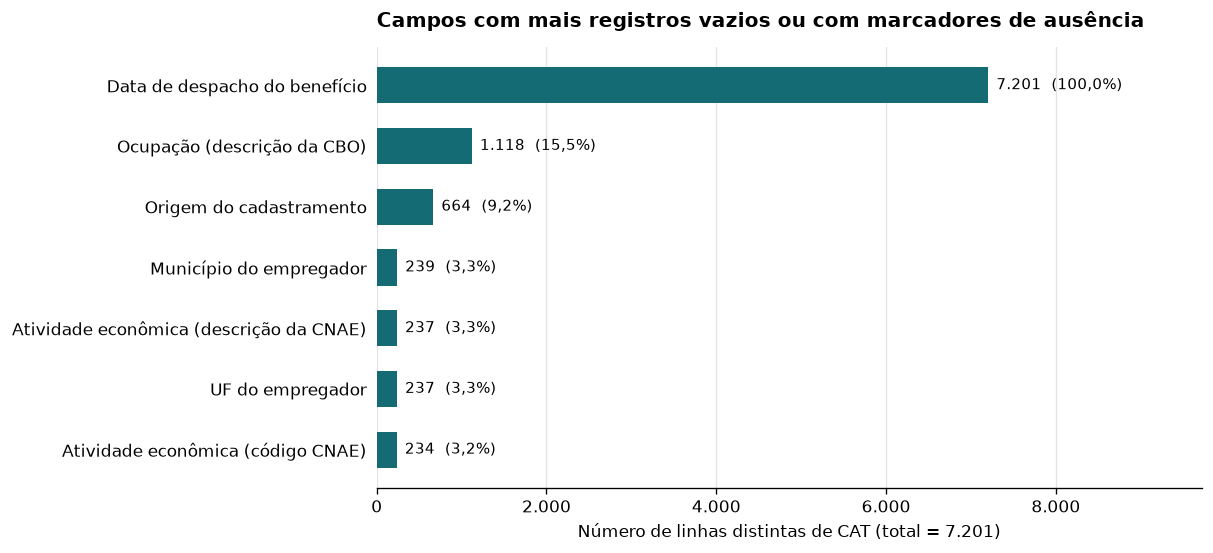

In [7]:
def inteiro_br(valor):
    return f"{valor:,.0f}".replace(",", ".")

def percentual_br(valor):
    return f"{valor:.1f}%".replace(".", ",")

def grafico_contagens(contagens, titulo, total, *, complemento="", altura=3.6):
    fig, ax = plt.subplots(figsize=(10, altura), layout="constrained")
    rotulos = [fill(str(rotulo), width=44) for rotulo in contagens.index]
    barras = ax.barh(rotulos, contagens, color="#146b73", height=0.6)
    anotacoes = [f"{inteiro_br(qtd)}  ({percentual_br(100 * qtd / total)})" for qtd in contagens]
    ax.bar_label(barras, labels=anotacoes, padding=5, fontsize=9)
    ax.invert_yaxis()
    ax.set_xlim(0, max(contagens.max(), 1) * 1.35)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5, integer=True))
    ax.xaxis.set_major_formatter(lambda valor, pos: inteiro_br(valor))
    ax.set_title(titulo, loc="left", fontweight="bold", pad=12)
    eixo = f"Número de linhas distintas de CAT (total = {inteiro_br(total)})"
    ax.set_xlabel(eixo + ("\n" + complemento if complemento else ""))
    ax.set_axisbelow(True)
    ax.grid(axis="x", color="#e1e5e5", linewidth=0.8)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(axis="y", length=0, pad=6)
    plt.show()

nomes_campos = {
    "data_despacho": "Data de despacho do benefício",
    "cbo_descricao": "Ocupação (descrição da CBO)",
    "origem_cadastro": "Origem do cadastramento",
    "municipio_empregador": "Município do empregador",
    "uf_empregador": "UF do empregador",
    "cnae_descricao": "Atividade econômica (descrição da CNAE)",
    "cnae": "Atividade econômica (código CNAE)",
}
mais_ausentes = faltas["Combinações distintas"].nlargest(7).rename(index=nomes_campos)
grafico_contagens(mais_ausentes, "Campos com mais registros vazios ou com marcadores de ausência",
                  n, altura=4.5)

Dos **620.163 registros** lidos, **10.295** trazem Ceará na UF do acidente e **8.849 linhas** atendem também ao recorte por data. A análise utiliza as **7.201 combinações distintas** que restam após retirar **1.648 cópias adicionais**. As **1.636 linhas** selecionadas no arquivo de junho já aparecem em maio. As duas colunas de data do acidente coincidem nos seis arquivos. Sem identificador individual de CAT, a deduplicação considera apenas a igualdade dos campos disponíveis.

### Dicionários de classificação

As tabelas locais completam rótulos truncados de CNAE, CBO e CID-10 quando o código tem correspondência única. Para o agente causador, a correspondência usa o início da descrição normalizada e exige um único candidato. A auditoria separa ausência de chave, falta de correspondência e ambiguidade.

In [8]:
texto = base[campos].apply(lambda coluna: coluna.str.strip())
sem_classe = ["", "{ñ class}"]
pares = []
for campo, zeros in [("cbo", "000000"), ("cid", ""), ("cnae", "0000")]:
    pares_validos = texto.loc[~texto[campo].isin([*sem_classe, zeros])
                              & ~texto[campo + "_descricao"].isin(sem_classe),
                              [campo, campo + "_descricao"]]
    ligacoes = pares_validos.drop_duplicates()
    pares.append({
        "Par": campo.upper(), "Linhas com ambos": len(pares_validos),
        "Códigos com vários rótulos": ligacoes[campo].value_counts().gt(1).sum(),
        "Rótulos com vários códigos": ligacoes[campo + "_descricao"].value_counts().gt(1).sum(),
    })
display(pd.DataFrame(pares).set_index("Par"))

def ler_referencia(nome, *, encoding="latin-1", sep=";"):
    return pd.read_csv(pasta / nome, encoding=encoding, sep=sep, dtype=str, keep_default_na=False)

cnae_ref = ler_referencia("cnae20.csv")
cbo_ref = ler_referencia("CBOs/CBO2002 - Ocupacao.csv")
cid_cat = ler_referencia("CIDs/CID-10-CATEGORIAS.CSV")
cid_sub = ler_referencia("CIDs/CID-10-SUBCATEGORIAS.CSV")
agentes_ref = ler_referencia("agente_causador_acidente_trabalho.csv", encoding="utf-8", sep=",")

def mapa_unico(chaves, rotulos):
    referencia = pd.DataFrame({"chave": chaves.str.strip(), "rótulo": rotulos.str.strip()})
    referencia = referencia[referencia.ne("").all(axis=1)].drop_duplicates()
    if referencia["chave"].duplicated().any():
        raise ValueError("Mais de uma descrição na referência para a mesma chave.")
    return referencia.set_index("chave")["rótulo"]

chave_cnae = cnae_ref["cod_classe"].str.replace(r"\D", "", regex=True)
assert chave_cnae.str.fullmatch(r"\d{5}").all()
mapa_cnae = mapa_unico(chave_cnae.str[:4], cnae_ref["denom_classe"])
mapa_cbo = mapa_unico(cbo_ref["CODIGO"], cbo_ref["TITULO"])
cid_ref = pd.concat([cid_cat.rename(columns={"CAT": "chave"}),
                     cid_sub.rename(columns={"SUBCAT": "chave"})], ignore_index=True)
mapa_cid = mapa_unico(cid_ref["chave"], cid_ref["DESCRICAO"])
chaves_referencia = pd.Series(
    {"CNAE": len(mapa_cnae), "CBO": len(mapa_cbo), "CID-10": len(mapa_cid)},
    name="Chaves distintas",
)
display(chaves_referencia.rename_axis("Referência").to_frame())

,Linhas com ambos,Códigos com vários rótulos,Rótulos com vários códigos
Par,,,
CBO,6082,0,0
CID,7188,0,0
CNAE,6964,0,31


,Chaves distintas
Referência,
CNAE,673
CBO,2725
CID-10,14233


In [9]:
def normalizar_agente(valor):
    sem_acento = unicodedata.normalize("NFKD", valor).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z0-9]+", " ", sem_acento.lower()).strip()

referencia_agentes = agentes_ref[["codigo", "descricao"]].drop_duplicates()
nomes_agentes = referencia_agentes["descricao"].map(normalizar_agente)
status_agente, rotulo_agente = {}, {}
for original in texto["agente"].unique():
    prefixo = normalizar_agente(original)
    if original in sem_classe or not prefixo:
        status_agente[original] = "Sem chave"
        continue
    candidatos = referencia_agentes.loc[nomes_agentes.str.startswith(prefixo)]
    if len(candidatos) == 1:
        status_agente[original] = "Associada"
        rotulo_agente[original] = candidatos["descricao"].iloc[0]
    else:
        status_agente[original] = "Ambígua" if len(candidatos) else "Sem correspondência"

cobertura = []
def auditar_referencia(campo, chaves, situacao):
    quadro = pd.DataFrame({"Chave": chaves, "Situação": situacao})
    grupos = quadro.groupby("Situação").agg(Registros=("Chave", "size"), Chaves=("Chave", "nunique"))
    grupos = grupos.reindex(["Associada", "Sem chave", "Sem correspondência", "Ambígua"], fill_value=0)
    grupos.insert(0, "Referência", campo)
    grupos["% do recorte"] = (100 * grupos["Registros"] / n).round(2)
    assert grupos["Registros"].sum() == n
    cobertura.append(grupos.reset_index())

for campo, mapa, ausentes in [
    ("cnae", mapa_cnae, [*sem_classe, "0000"]),
    ("cbo", mapa_cbo, [*sem_classe, "000000"]),
    ("cid", mapa_cid, sem_classe),
]:
    chave = texto[campo]
    if campo == "cid":
        chave = chave.str.upper().str.replace(".", "", regex=False)
    base[campo + "_rotulo"] = chave.mask(chave.isin(ausentes)).map(mapa)
    situacao = pd.Series("Associada", index=base.index)
    situacao.loc[base[campo + "_rotulo"].isna()] = "Sem correspondência"
    situacao.loc[chave.isin(ausentes)] = "Sem chave"
    auditar_referencia(campo.upper(), chave, situacao)

base["agente_rotulo"] = texto["agente"].map(rotulo_agente)
auditar_referencia("Agente", texto["agente"], texto["agente"].map(status_agente))
assert len(base) == n and base.index.is_unique
display(pd.concat(cobertura).set_index(["Referência", "Situação"]))

Registros  Chaves  % do recorte
Referência Situação                                            
CNAE       Associada                 6964     299         96.71
           Sem chave                  234       1          3.25
           Sem correspondência          3       3          0.04
           Ambígua                      0       0          0.00
CBO        Associada                 7199     619         99.97
           Sem chave                    1       1          0.01
           Sem correspondência          1       1          0.01
           Ambígua                      0       0          0.00
CID        Associada                 7201     922        100.00
           Sem chave                    0       0          0.00
           Sem correspondência          0       0          0.00
           Ambígua                      0       0          0.00
Agente     Associada                 5952     157         82.66
           Sem chave                  139       1          1.93
           Sem correspondência        393      32          5.46
           Ambígua                    717       7          9.96

In [10]:
def categoria(serie, extras=()):
    marcadores_ausencia = [valor.lower() for valor in [*sem_classe, *extras]]
    return serie.mask(serie.str.lower().isin(marcadores_ausencia), "Sem informação")


def grupo_classificado(campo, marcador_zero):
    codigo = texto[campo]
    rotulo = base[campo + "_rotulo"].fillna("Rótulo sem correspondência")
    return categoria(codigo + " · " + rotulo).mask(codigo.isin([*sem_classe, marcador_zero]), "Sem informação")

def agrupar_principais(serie, limite=5):
    frequentes = serie[serie.ne("Sem informação")].value_counts().head(limite).index
    return serie.where(serie.isin([*frequentes, "Sem informação"]), "Demais categorias")

cnae = grupo_classificado("cnae", "0000")
cbo = grupo_classificado("cbo", "000000")
parte = categoria(texto["parte_atingida"])
lesao = categoria(texto["natureza_lesao"])
tipo = categoria(texto["tipo"])

## 2. Qual é o perfil dos trabalhadores acidentados?

**Questão 1.** Como os registros se distribuem por sexo e faixa etária? O perfil por sexo muda entre as faixas?

A idade é calculada em anos completos na data do acidente. Nascimentos ilegíveis ou posteriores à ocorrência ficam na categoria sem idade válida. Ausências no campo de sexo ficam visíveis nos totais.

,Registros,% do grupo
Sexo registrado,,
Masculino,3856,53.55
Feminino,3336,46.33
Sem informação,9,0.12


,Registros,% do grupo
Faixa etária,,
Até 17,9,0.12
18 a 29,2092,29.05
30 a 39,1979,27.48
40 a 49,1919,26.65
50 a 59,962,13.36
60 ou mais,240,3.33
Sem idade válida,0,0.00


Sexo,Feminino,Masculino,Sem informação,Total
Idade no acidente,,,,
Até 17,5,4,0,9
18 a 29,795,1290,7,2092
30 a 39,917,1062,0,1979
40 a 49,1022,895,2,1919
50 a 59,491,471,0,962
60 ou mais,106,134,0,240
Sem idade válida,0,0,0,0
Total,3336,3856,9,7201


,Registros,Idades válidas,Mínima (anos),Mediana (anos),Máxima (anos),Nascimentos com data ilegível ou ausente,Nascimentos posteriores ao acidente
0,7201,7201,15,37.0,84,0,0


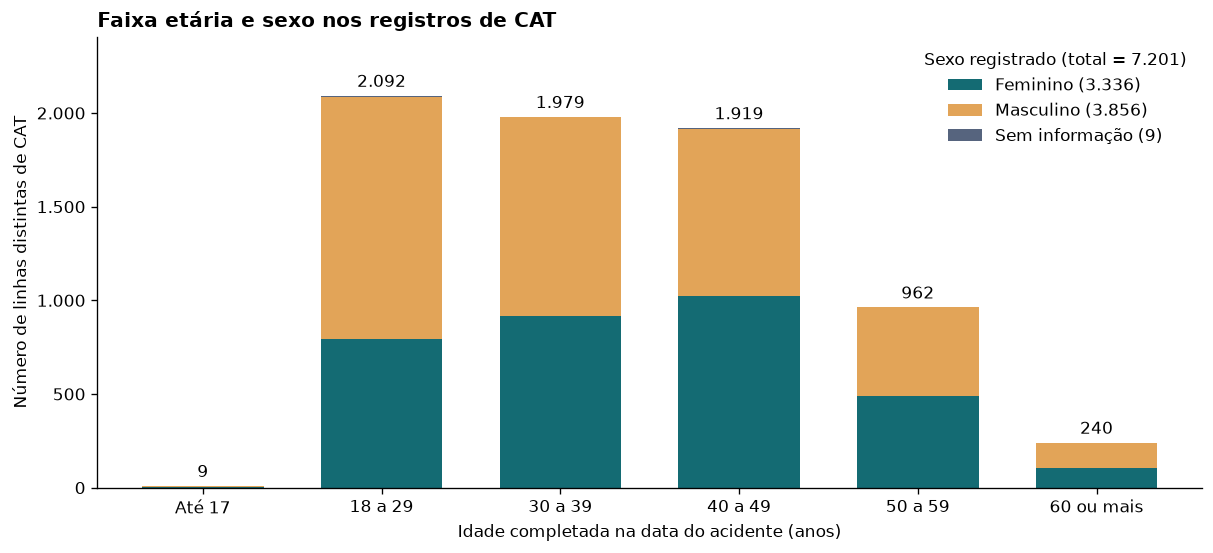

In [11]:
nascimento = ler_data(base["data_nascimento"])
ocorrencia = acidente.loc[base.index]
antes_do_aniversario = ((ocorrencia.dt.month < nascimento.dt.month)
                        | (ocorrencia.dt.month.eq(nascimento.dt.month) & ocorrencia.dt.day.lt(nascimento.dt.day)))
idade = (ocorrencia.dt.year - nascimento.dt.year - antes_do_aniversario.astype(int)).where(nascimento.le(ocorrencia))
faixas = ["Até 17", "18 a 29", "30 a 39", "40 a 49", "50 a 59", "60 ou mais"]
faixa = pd.cut(idade, [0, 18, 30, 40, 50, 60, float("inf")], labels=faixas, right=False)
faixa = faixa.cat.add_categories(["Sem idade válida"]).fillna("Sem idade válida")
sexo = categoria(texto["sexo"], ["Indeterminado", "Não Informado"])
perfil_sexo = pd.crosstab(faixa.rename("Idade no acidente"), sexo.rename("Sexo"), dropna=False,
                          margins=True, margins_name="Total")
display(frequencia(sexo).rename_axis("Sexo registrado"))
display(frequencia(faixa).reindex([*faixas, "Sem idade válida"]).rename_axis("Faixa etária"))
display(perfil_sexo)
display(pd.DataFrame({
    "Registros": [n], "Idades válidas": [idade.count()],
    "Mínima (anos)": [idade.min()], "Mediana (anos)": [idade.median()], "Máxima (anos)": [idade.max()],
    "Nascimentos com data ilegível ou ausente": [nascimento.isna().sum()],
    "Nascimentos posteriores ao acidente": [nascimento.gt(ocorrencia).sum()],
}))

por_idade = perfil_sexo.drop(index="Total", columns="Total")
por_idade = por_idade.loc[por_idade.sum(axis=1).gt(0)]
fig, ax = plt.subplots(figsize=(10, 4.5), layout="constrained")
por_idade.plot.bar(ax=ax, stacked=True, rot=0, width=0.68,
                   color={"Feminino": "#146b73", "Masculino": "#e2a458", "Sem informação": "#56647e"})
totais_idade = por_idade.sum(axis=1)
ax.bar_label(ax.containers[-1], labels=[inteiro_br(v) for v in totais_idade], padding=3)
ax.set_ylim(0, totais_idade.max() * 1.15)
ax.set(xlabel="Idade completada na data do acidente (anos)", ylabel="Número de linhas distintas de CAT")
ax.set_title("Faixa etária e sexo nos registros de CAT", loc="left", fontweight="bold")
ax.yaxis.set_major_formatter(lambda valor, pos: inteiro_br(valor))
ax.legend(title=f"Sexo registrado (total = {inteiro_br(n)})",
          labels=[f"{nome} ({inteiro_br(por_idade[nome].sum())})" for nome in por_idade],
          frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

<details>
<summary><strong>Ver resposta à questão 1</strong></summary>

Das **7.201 linhas distintas**, **3.856 (53,55%)** informam sexo masculino, **3.336 (46,33%)** informam sexo feminino e **9 (0,12%)** estão sem informação. A idade pôde ser calculada em todas as linhas e teve mediana de **37 anos**.

A faixa de **18 a 29 anos** é a mais frequente, com **2.092 registros (29,05%)**. Nessa faixa, **1.290 de 2.092 (61,66%)** informam sexo masculino. Entre **40 e 49 anos**, **1.022 de 1.919 (53,26%)** informam sexo feminino.

</details>

## 3. Quais atividades econômicas apresentam mais acidentes registrados?

**Questão 2.** Quais classes e setores da CNAE do empregador concentram mais registros?

As classes detalham a atividade econômica e as seções agrupam essas classes em setores. O gráfico mostra as cinco classes mais frequentes. Os percentuais usam as 7.201 linhas distintas, inclusive os registros sem classificação.

,Registros,% do grupo
Classe CNAE do empregador,,
8660 · Atividades de apoio à gestão de saúde,780,10.83
8610 · Atividades de atendimento hospitalar,725,10.07
5611 · Restaurantes e outros estabelecimentos de serviços de alimentação e bebidas,286,3.97
4120 · Construção de edifícios,208,2.89
"4711 · Comércio varejista de mercadorias em geral, com predominância de produtos alimentícios - hipermercados e supermercados",198,2.75
Demais categorias,4770,66.24
Sem informação,234,3.25


,Registros,% do grupo
Seção CNAE do empregador,,
Q · Saúde humana e serviços sociais,1847,25.65
G · Comércio; reparação de veículos automotores e motocicletas,1023,14.21
N · Atividades administrativas e serviços complementares,782,10.86
"H · Transporte, armazenagem e correio",522,7.25
F · Construção,471,6.54
I · Alojamento e alimentação,444,6.17
"E · Água, esgoto, atividades de gestão de resíduos e descontaminação",349,4.85
C · Indústrias de transformação,347,4.82
"K · Atividades financeiras, de seguros e serviços relacionados",342,4.75


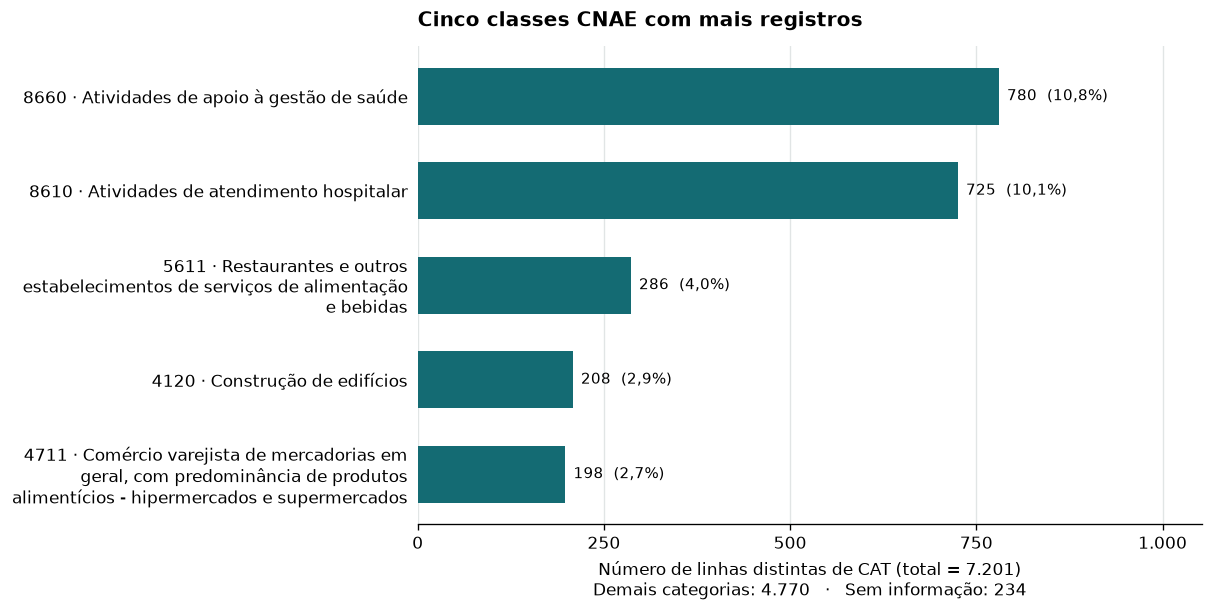

In [12]:
chaves_secao = cnae_ref["cod_secao"] + " · " + cnae_ref["denom_secao"].str.capitalize()
mapa_secao = mapa_unico(chave_cnae.str[:4], chaves_secao)
sem_cnae = texto["cnae"].isin([*sem_classe, "0000"])
secao_cnae = (
    texto["cnae"].map(mapa_secao)
    .fillna("Sem correspondência")
    .mask(sem_cnae, "Sem informação")
)

classes = frequencia(agrupar_principais(cnae))
principais = classes.drop(["Sem informação", "Demais categorias"], errors="ignore")
restantes = classes.drop(index=principais.index).reindex(["Demais categorias", "Sem informação"], fill_value=0)
display(pd.concat([principais, restantes]).rename_axis("Classe CNAE do empregador"))

setores = frequencia(secao_cnae)
display(setores.rename_axis("Seção CNAE do empregador"))

complemento = "   ·   ".join(
    f"{categoria_cnae}: {inteiro_br(qtd)}" for categoria_cnae, qtd in restantes["Registros"].items()
)
grafico_contagens(principais["Registros"], "Cinco classes CNAE com mais registros", n,
                  complemento=complemento, altura=5)

<details>
<summary><strong>Ver resposta à questão 2</strong></summary>

**Apoio à gestão de saúde (CNAE 8660)** aparece em **780 registros (10,83%)** e **atendimento hospitalar (CNAE 8610)**, em **725 (10,07%)**. Juntas, as duas classes somam **1.505 de 7.201 (20,90%)**. Por setor, **Saúde humana e serviços sociais** lidera com **1.847 registros (25,65%)**, seguida de **Comércio e reparação de veículos automotores e motocicletas**, com **1.023 (14,21%)**.

Há **234 registros sem código CNAE informado** e **3** com código sem correspondência no dicionário.

</details>

## 4. Quais são os principais tipos de acidentes?

**Questão 3.** Como as categorias típico, trajeto e doença se distribuem no recorte?

A distribuição por tipo usa as linhas distintas do recorte. O cruzamento com a parte do corpo atingida usa como denominador o total de cada tipo.

,Registros,% do grupo
Tipo de acidente,,
Típico,4989,69.28
Trajeto,1693,23.51
Doença,519,7.21


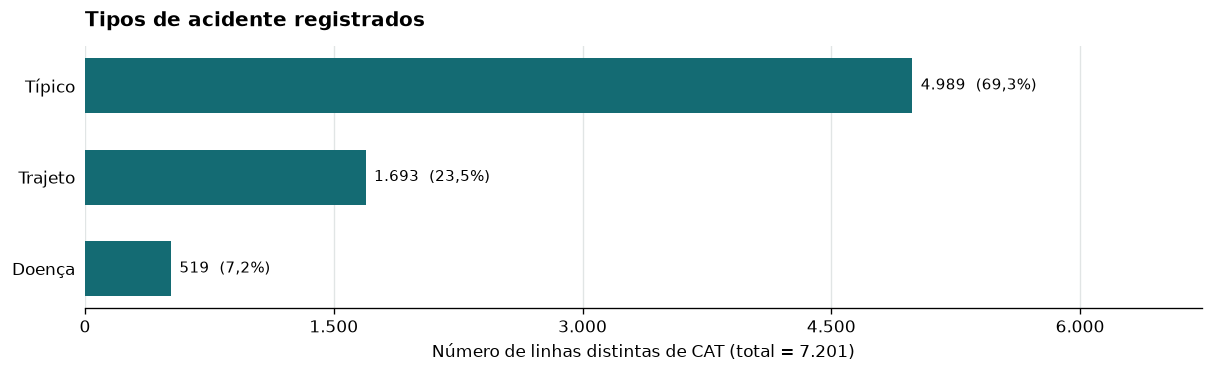

In [13]:
ordem_tipos = ["Típico", "Trajeto", "Doença"]
def frequencia_tipos(serie):
    contagens = serie.value_counts()
    return contagens.reindex([*ordem_tipos, *contagens.index.difference(ordem_tipos)], fill_value=0)

contagens_tipo = frequencia_tipos(tipo)
display(frequencia(tipo).reindex(contagens_tipo.index, fill_value=0).rename_axis("Tipo de acidente"))
grafico_contagens(contagens_tipo, "Tipos de acidente registrados", n, altura=3)

Parte atingida,Dedo,Pe (Exceto Artelhos),Mao (Exceto Punho ou,Joelho,Partes Multiplas - A,Demais categorias,Total
Tipo de acidente,,,,,,,
Doença,6,6,3,6,10,488,519
Trajeto,58,166,51,128,218,1072,1693
Típico,1331,458,394,271,167,2368,4989


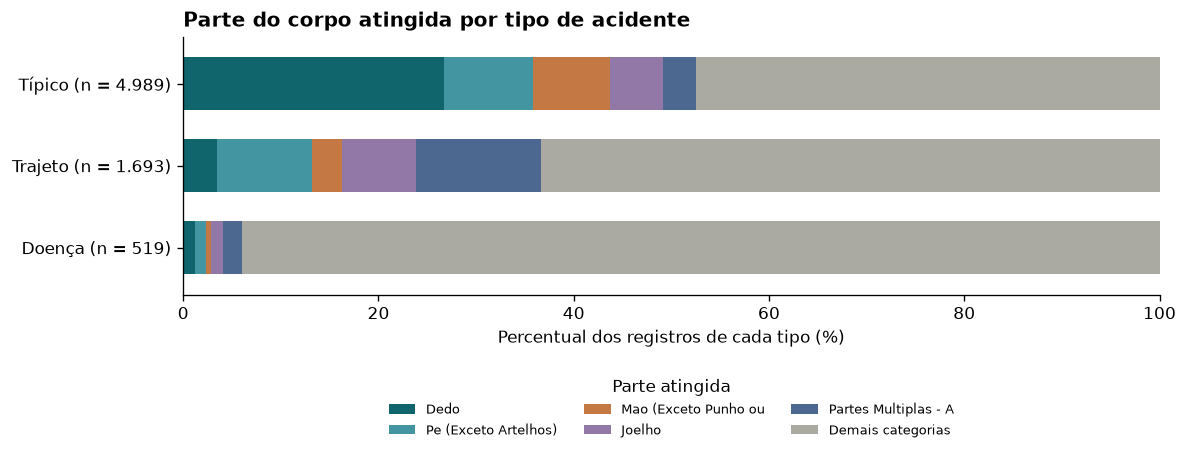

In [14]:
partes_principais = agrupar_principais(parte)
cruzamento = pd.crosstab(tipo.rename("Tipo de acidente"), partes_principais.rename("Parte atingida"))
ordem = [nome for nome in partes_principais.value_counts().index if nome != "Demais categorias"]
if "Demais categorias" in cruzamento:
    ordem.append("Demais categorias")
cruzamento = cruzamento[ordem]
totais_tipo = cruzamento.sum(axis=1)
display(cruzamento.assign(Total=totais_tipo))

percentuais = 100 * cruzamento.div(totais_tipo, axis=0)
cores = ["#10656c", "#4396a1", "#c47843", "#9178a6", "#4c6790", "#aaa9a2", "#dfd2ba"]
ax = percentuais.plot.barh(stacked=True, color=cores[:len(ordem)], figsize=(10, 4.2), width=0.65)
ax.set(xlim=(0, 100), xlabel="Percentual dos registros de cada tipo (%)", ylabel="",
       title="Parte do corpo atingida por tipo de acidente")
ax.spines[["top", "right"]].set_visible(False)
ax.set_yticks(range(len(totais_tipo)), [f"{tipo_nome} (n = {inteiro_br(total)})" for tipo_nome, total in totais_tipo.items()])
ax.legend(title="Parte atingida", loc="upper center", bbox_to_anchor=(0.5, -0.28),
          ncol=3, frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

<details>
<summary><strong>Ver resposta à questão 3</strong></summary>

O **acidente típico** é o mais registrado, com **4.989 de 7.201 (69,28%)**. Os acidentes de **trajeto** têm **1.693 registros (23,51%)** e as **doenças**, **519 (7,21%)**. Todas as linhas têm tipo informado.

O dedo foi a parte do corpo mais citada, em **1.395 registros (19,37%)**. Aparece em **1.331 de 4.989 registros típicos (26,68%)** e em **58 de 1.693 registros de trajeto (3,43%)**.

</details>

### Ocupação, natureza da lesão e parte atingida

As tabelas agrupam as categorias além das cinco mais frequentes e preservam as ausências. O quadro de categorias raras considera aquelas com até cinco registros no recorte.

In [15]:
resumo_categorias = []
for titulo, serie in [("Ocupação (CBO)", cbo),
                      ("Parte do corpo atingida", parte), ("Natureza da lesão", lesao)]:
    display(frequencia(agrupar_principais(serie)).rename_axis(titulo))
    freq_conhecidas = serie[serie.ne("Sem informação")].value_counts()
    raras = freq_conhecidas[freq_conhecidas.le(5)]
    resumo_categorias.append({
        "Campo": titulo, "Registros": len(serie), "Categorias informadas": len(freq_conhecidas),
        "Categorias com até 5 registros": len(raras), "Registros nessas categorias": raras.sum(),
        "Sem informação": serie.eq("Sem informação").sum(),
    })

display(pd.DataFrame(resumo_categorias).set_index("Campo"))

,Registros,% do grupo
Ocupação (CBO),,
Demais categorias,5279,73.31
322205 · Técnico de enfermagem,890,12.36
514320 · Faxineiro,359,4.99
223505 · Enfermeiro,249,3.46
514205 · Coletor de lixo domiciliar,238,3.31
411010 · Assistente administrativo,185,2.57
Sem informação,1,0.01


,Registros,% do grupo
Parte do corpo atingida,,
Demais categorias,3928,54.55
Dedo,1395,19.37
Pe (Exceto Artelhos),630,8.75
Mao (Exceto Punho ou,448,6.22
Joelho,405,5.62
Partes Multiplas - A,395,5.49


,Registros,% do grupo
Natureza da lesão,,
Demais categorias,2659,36.93
Lesao Imediata,1172,16.28
"Corte, Laceracao, Fe",1103,15.32
Fratura,864,12.00
"Contusao, Esmagament",709,9.85
"Distensao, Torcao",694,9.64


,Registros,Categorias informadas,Categorias com até 5 registros,Registros nessas categorias,Sem informação
Campo,,,,,
Ocupação (CBO),7201,620,445,891,1
Parte do corpo atingida,7201,42,4,11,0
Natureza da lesão,7201,26,4,9,0


## 5. Como os acidentes estão distribuídos nos municípios do Ceará?

**Questão 4.** Os campos da base permitem comparar os municípios onde os acidentes ocorreram?

O inventário identifica os campos geográficos que vieram nos CSVs. A tabela seguinte usa o campo **município do empregador** para ilustrar seu conteúdo e inclui os registros sem município informado.

In [16]:
geografia_origem = esquema.loc[
    ["uf_acidente", "uf_empregador", "municipio_empregador"], ["Posição", "Cabeçalho original"]
].copy()
geografia_origem["Informação registrada"] = [
    "UF do acidente", "UF do empregador", "Município do empregador",
]
display(geografia_origem.reset_index(drop=True))

municipio = categoria(texto["municipio_empregador"], ["000000-Ignorado"])
municipio_ce = (
    municipio.str.match(r"^23[0-9]{4}-")
    & texto["uf_empregador"].eq("Ceará")
)
origem_municipal = pd.Series("Demais municípios do empregador", index=base.index)
origem_municipal = origem_municipal.mask(municipio.str.startswith("530010-"), "Brasília (DF)")
origem_municipal = origem_municipal.mask(municipio_ce, municipio)
origem_municipal = origem_municipal.mask(municipio.eq("Sem informação"), "Sem informação de município")
display(frequencia(origem_municipal)
        .rename_axis("Município registrado para o empregador"))

,Posição,Cabeçalho original,Informação registrada
0,19,UF Munic. Acidente,UF do acidente
1,20,UF Munic. Empregador,UF do empregador
2,13,Munic Empr,Município do empregador


,Registros,% do grupo
Município registrado para o empregador,,
Brasília (DF),6668,92.60
Demais municípios do empregador,284,3.94
Sem informação de município,239,3.32
230440-Fortaleza,9,0.12
230428-Eusébio,1,0.01


<details>
<summary><strong>Ver resposta à questão 4</strong></summary>

**A distribuição dos acidentes por município do Ceará não pode ser determinada com estes arquivos.** A localização da ocorrência está disponível no nível da UF. O campo `Munic Empr` identifica o município registrado para o empregador.

Das **7.201 linhas distintas**, **6.668 (92,60%)** indicam empregador em **Brasília**, **9** em **Fortaleza** e **1** em **Eusébio**. Em **239** linhas, o município do empregador está sem informação. Uma comparação municipal da ocorrência exigiria um campo que identificasse diretamente o município de cada acidente.

</details>

## 6. Existe diferença entre a data do acidente e a emissão da CAT?

**Questão 5.** Quantos dias corridos decorrem entre a ocorrência e a emissão? O intervalo observado varia por tipo?

O prazo é calculado pela data de emissão menos a data do acidente. A tabela identifica datas sem intervalo calculável e emissões anteriores à ocorrência. As estatísticas de prazo usam intervalos válidos e não negativos.

In [17]:
dias = (emissao.loc[base.index] - ocorrencia).dt.days
faixas_prazo = ["Antes do acidente", "No mesmo dia", "1 a 7 dias", "8 a 30 dias", "Mais de 30 dias"]
prazo = pd.cut(dias, [-float("inf"), -1, 0, 7, 30, float("inf")], labels=faixas_prazo)
prazo = prazo.cat.add_categories(["Sem intervalo válido"]).fillna("Sem intervalo válido")
display(frequencia(prazo).reindex([*faixas_prazo, "Sem intervalo válido"]).rename_axis("Prazo de emissão"))

dias_validos = dias.where(dias.ge(0))
resumo_dias = pd.Series({
    "Intervalos válidos": dias_validos.count(),
    "Mínimo (dias)": dias_validos.min(),
    "Mediana (dias)": dias_validos.median(),
    "Percentil 90 (dias)": dias_validos.quantile(.90),
    "Máximo (dias)": dias_validos.max(),
}, name="Linhas distintas")
display(resumo_dias.round(1).to_frame())

prazos_por_tipo = dias_validos.groupby(tipo).agg(Registros="size", Intervalos_válidos="count", Mediana_dias="median")
display(prazos_por_tipo.rename_axis("Tipo de acidente").rename(columns={
    "Intervalos_válidos": "Intervalos válidos", "Mediana_dias": "Mediana (dias)",
}).sort_values("Registros", ascending=False))

,Registros,% do grupo
Prazo de emissão,,
Antes do acidente,0,0.00
No mesmo dia,388,5.39
1 a 7 dias,4343,60.31
8 a 30 dias,1923,26.70
Mais de 30 dias,547,7.60
Sem intervalo válido,0,0.00


,Linhas distintas
Intervalos válidos,7201.0
Mínimo (dias),0.0
Mediana (dias),4.0
Percentil 90 (dias),25.0
Máximo (dias),191.0


,Registros,Intervalos válidos,Mediana (dias)
Tipo de acidente,,,
Típico,4989,4989,4.0
Trajeto,1693,1693,5.0
Doença,519,519,20.0


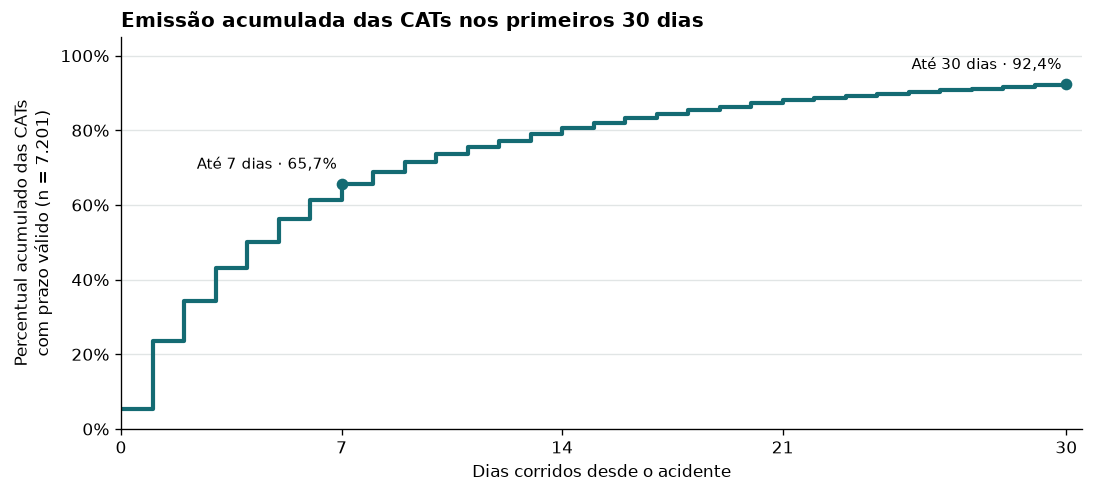

In [18]:
intervalos_validos = dias[dias.ge(0)]
ate_dia = (intervalos_validos.value_counts().reindex(range(31), fill_value=0)
           .cumsum().div(len(intervalos_validos)).mul(100))

fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
ax.step(ate_dia.index, ate_dia, where="post", color="#146b73", linewidth=2.5)
for dia in (7, 30):
    acumulado = ate_dia.loc[dia]
    ax.plot(dia, acumulado, "o", color="#146b73")
    ax.annotate(f"Até {dia} dias · {percentual_br(acumulado)}", (dia, acumulado),
                xytext=(-3, 9), textcoords="offset points", ha="right", fontsize=9)
ax.set(xlim=(0, 30.5), ylim=(0, 105), xticks=[0, 7, 14, 21, 30],
       xlabel="Dias corridos desde o acidente",
       ylabel=f"Percentual acumulado das CATs\ncom prazo válido (n = {inteiro_br(len(intervalos_validos))})")
ax.yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
ax.set_title("Emissão acumulada das CATs nos primeiros 30 dias", loc="left", fontweight="bold")
ax.grid(axis="y", color="#e1e5e5", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

<details>
<summary><strong>Ver resposta à questão 5</strong></summary>

O prazo mediano foi de **4 dias corridos**. Dos **7.201 registros**, **388 (5,39%)** foram emitidos no mesmo dia, **4.731 (65,70%)** até o sétimo dia e **547 (7,60%)** depois de 30 dias. Todos os intervalos puderam ser calculados e foram não negativos. O maior prazo foi de **191 dias**.

A mediana foi de **20 dias** nos **519** registros de doença, **5 dias** nos **1.693** de trajeto e **4 dias** nos **4.989** típicos.

</details>

## 7. Como os registros variaram no primeiro semestre de 2026?

**Questão 6.** Como os registros distintos variaram por mês do acidente?

O gráfico usa a data do acidente das linhas distintas. A primeira tabela inclui as emissões posteriores a junho já disponíveis. A segunda mostra quanto a contagem por mês era afetada pelas repetições.

,Linhas distintas,% das linhas distintas,Emitidas após junho
Mês do acidente,,,
Jan,1115,15.48,8
Fev,1102,15.30,10
Mar,1264,17.55,13
Abr,1202,16.69,17
Mai,1305,18.12,47
Jun,1213,16.84,262


,Antes da deduplicação,Linhas distintas,Cópias adicionais
Mês do acidente,,,
Jan,1136,1115,21
Fev,1122,1102,20
Mar,1301,1264,37
Abr,1256,1202,54
Mai,1608,1305,303
Jun,2426,1213,1213


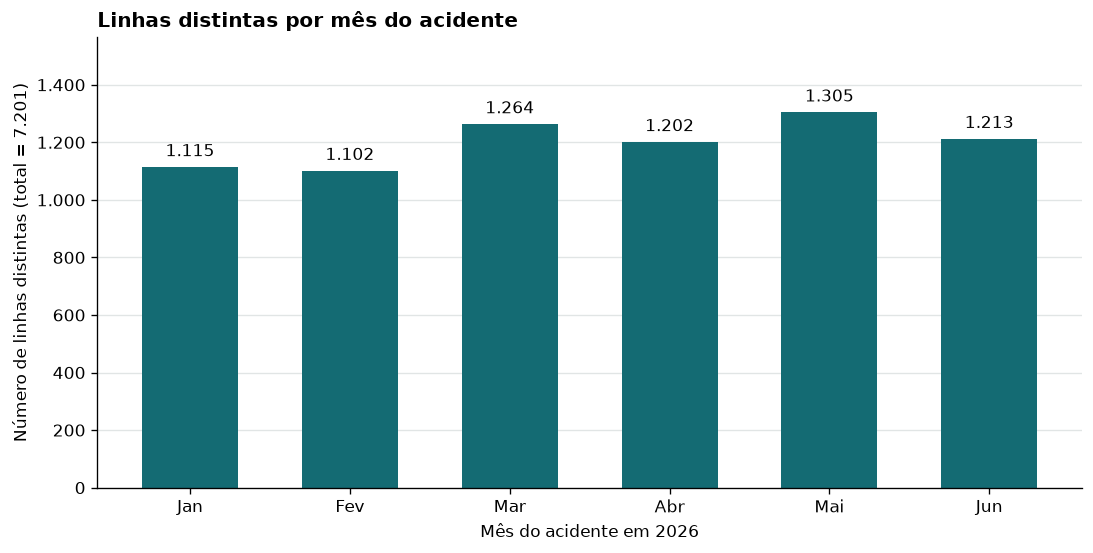

In [19]:
meses = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun"]
ordem_meses = range(1, 7)
mes_ocorrencia = ocorrencia.dt.month
contagens_mensais = mes_ocorrencia.value_counts().reindex(ordem_meses, fill_value=0)
emissao_posterior = emissao.loc[base.index].gt(fim)
emissoes_posteriores = emissao_posterior.groupby(mes_ocorrencia).sum().reindex(ordem_meses, fill_value=0)
mensal = pd.DataFrame({
    "Linhas distintas": contagens_mensais,
    "% das linhas distintas": (100 * contagens_mensais / n).round(2),
    "Emitidas após junho": emissoes_posteriores,
})
mensal.index = pd.Index(meses, name="Mês do acidente")
display(mensal)

mes_ocorrencia_bruto = acidente.loc[recorte_com_repeticoes.index].dt.month
contagens_brutas = mes_ocorrencia_bruto.value_counts().reindex(ordem_meses, fill_value=0)
auditoria_mensal = pd.DataFrame({
    "Antes da deduplicação": contagens_brutas,
    "Linhas distintas": contagens_mensais,
    "Cópias adicionais": contagens_brutas - contagens_mensais,
})
auditoria_mensal.index = mensal.index
display(auditoria_mensal)

fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
barras = ax.bar(mensal.index, mensal["Linhas distintas"], color="#146b73", width=0.6)
ax.bar_label(barras, labels=[inteiro_br(qtd) for qtd in mensal["Linhas distintas"]], padding=4)
ax.set(title="Linhas distintas por mês do acidente", xlabel="Mês do acidente em 2026",
       ylabel=f"Número de linhas distintas (total = {inteiro_br(n)})",
       ylim=(0, mensal["Linhas distintas"].max() * 1.2))
ax.grid(axis="y", color="#e1e5e5", linewidth=0.8)
ax.set_axisbelow(True)
ax.yaxis.set_major_formatter(lambda valor, pos: inteiro_br(valor))
plt.show()

<details>
<summary><strong>Ver resposta à questão 6</strong></summary>

Entre as **7.201 linhas distintas**, **maio** teve o maior volume, com **1.305 registros**, e **fevereiro** teve o menor, com **1.102**. **Junho** somou **1.213**. A contagem anterior à deduplicação apresentava junho como pico, com **2.426 linhas**, em uma base com forte sobreposição entre os arquivos de maio e junho.

Das **7.201 linhas distintas**, **357 (4,96%)** foram emitidas após junho. Dessas, **262** se referem a acidentes ocorridos em junho. A série representa as comunicações disponíveis nos arquivos e pode mudar com novas emissões ou atualizações.

</details>

## 8. Quais setores econômicos e tipos de acidente concentram os registros com óbito?

**Questão 7 (extra).** Quais setores econômicos e tipos de acidente concentram os registros com óbito — e eles coincidem com os que lideram o volume total de CATs?

A análise contabiliza os registros com indicação de óbito (`Sim`) entre as 7.201 linhas distintas. Para não confundir volume de notificações com gravidade, as tabelas apresentam, além das contagens absolutas, o total de CATs de cada grupo e a proporção descritiva de óbitos por 1.000 CATs. Como o total de óbitos no semestre é pequeno (`n = 27`), as proporções são sensíveis a variações unitárias e não representam taxas populacionais de risco.

In [20]:
obito = categoria(texto["obito"])
display(frequencia(obito).rename_axis("Indicação de óbito"))

eh_obito = obito.eq("Sim")
total_obitos = int(eh_obito.sum())

def resumo_obitos(serie, nome_indice):
    quadro = pd.DataFrame({"grupo": serie, "obito": eh_obito})
    resumo = quadro.groupby("grupo", observed=False).agg(
        Total_CATs=("obito", "size"),
        Obitos=("obito", "sum"),
    )
    resumo["% dos óbitos"] = (100 * resumo["Obitos"] / total_obitos).round(2)
    resumo["Óbitos / 1.000 CATs"] = (1000 * resumo["Obitos"] / resumo["Total_CATs"]).round(1)
    resumo = resumo.rename(columns={"Total_CATs": "Total de CATs", "Obitos": "Óbitos"})
    resumo.index.name = nome_indice
    return resumo

por_setor_obito = resumo_obitos(secao_cnae, "Seção CNAE do empregador")
cruzamento_setor_tipo = pd.crosstab(secao_cnae[eh_obito], tipo[eh_obito]).reindex(
    columns=["Trajeto", "Típico"], fill_value=0
)
por_setor_obito = (
    por_setor_obito.loc[por_setor_obito["Óbitos"].gt(0)]
    .join(cruzamento_setor_tipo)
    .sort_values(["Óbitos", "Óbitos / 1.000 CATs"], ascending=[False, False])
)
display(por_setor_obito)

por_tipo_obito = resumo_obitos(tipo, "Tipo de acidente").reindex(ordem_tipos)
display(por_tipo_obito)

por_sexo_obito = resumo_obitos(sexo, "Sexo registrado")
display(por_sexo_obito.loc[por_sexo_obito["Óbitos"].gt(0)].sort_values("Óbitos", ascending=False))

print(
    f"Idade mediana nos óbitos: {idade[eh_obito].median():.0f} anos "
    f"(geral: {idade.median():.0f} anos; intervalo nos óbitos: "
    f"{idade[eh_obito].min():.0f} a {idade[eh_obito].max():.0f} anos)."
)

agentes_obito = base.loc[eh_obito, "agente_rotulo"].fillna(texto.loc[eh_obito, "agente"])
display(
    frequencia(agentes_obito)
    .head(6)
    .rename(columns={"% das linhas": "% dos óbitos"})
    .rename_axis("Principais agentes causadores nos registros com óbito")
)

,Registros,% do grupo
Indicação de óbito,,
Não,7174,99.63
Sim,27,0.37


,Total de CATs,Óbitos,% dos óbitos,Óbitos / 1.000 CATs,Trajeto,Típico
Seção CNAE do empregador,,,,,,
N · Atividades administrativas e serviços complementares,782,6,22.22,7.7,5,1
F · Construção,471,5,18.52,10.6,2,3
G · Comércio; reparação de veículos automotores e motocicletas,1023,5,18.52,4.9,4,1
Sem informação,234,4,14.81,17.1,2,2
"H · Transporte, armazenagem e correio",522,2,7.41,3.8,1,1
Q · Saúde humana e serviços sociais,1847,2,7.41,1.1,0,2
C · Indústrias de transformação,347,1,3.70,2.9,0,1
"K · Atividades financeiras, de seguros e serviços relacionados",342,1,3.70,2.9,0,1
I · Alojamento e alimentação,444,1,3.70,2.3,1,0


,Total de CATs,Óbitos,% dos óbitos,Óbitos / 1.000 CATs
Tipo de acidente,,,,
Típico,4989,12,44.44,2.4
Trajeto,1693,15,55.56,8.9
Doença,519,0,0.00,0.0


,Total de CATs,Óbitos,% dos óbitos,Óbitos / 1.000 CATs
Sexo registrado,,,,
Masculino,3856,24,88.89,6.2
Feminino,3336,3,11.11,0.9


Idade mediana nos óbitos: 44 anos (geral: 37 anos; intervalo nos óbitos: 21 a 62 anos).


,Registros,% do grupo
Principais agentes causadores nos registros com óbito,,
"Veículo, NIC",4,14.81
Veículo rodoviário motorizado,4,14.81
"Motocicleta, motoneta",4,14.81
Rua e estrada - superfície utilizada para sustentar pessoas,3,11.11
Agente do acidente inexistente,2,7.41
"Edifício ou estrutura (exceto piso, superfície de sustentação ou área de circulação), NIC",1,3.70


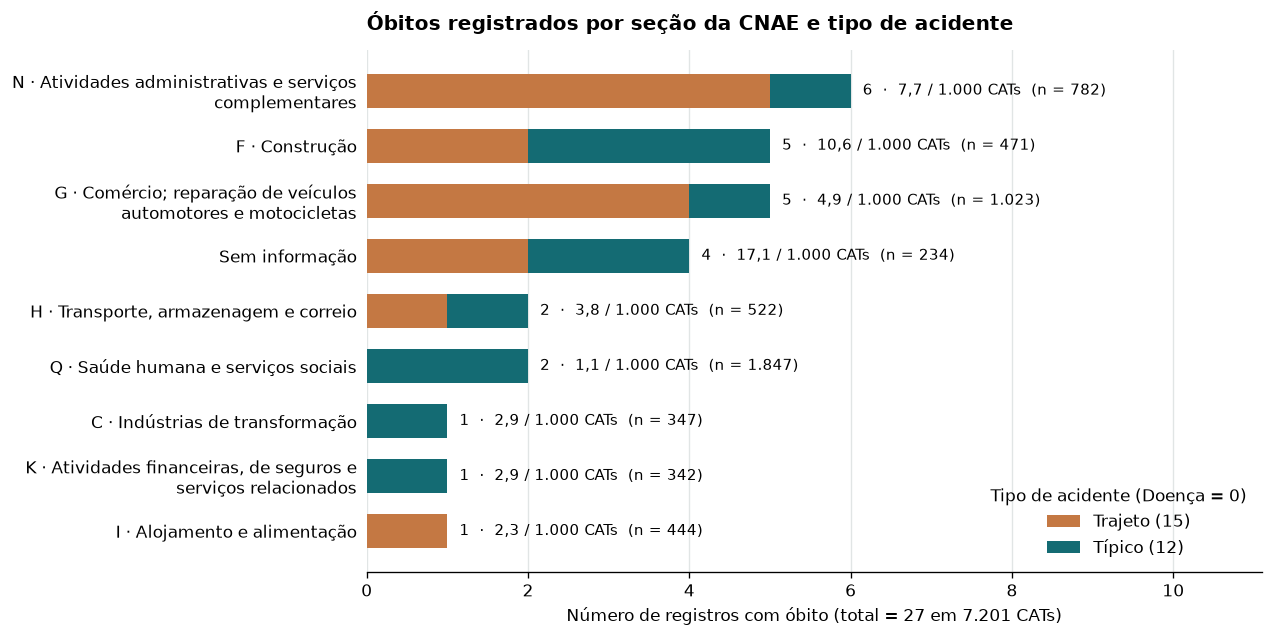

In [21]:
fig_path = Path("figuras/atividade_01/obitos_setor_tipo.png")
fig_path.parent.mkdir(parents=True, exist_ok=True)

dados_plot = por_setor_obito.copy()
rotulos = [fill(str(nome), width=42) for nome in dados_plot.index]
y = range(len(dados_plot))

fig, ax = plt.subplots(figsize=(10.5, 5.2), layout="constrained")
b_trajeto = ax.barh(y, dados_plot["Trajeto"], color="#c47843", height=0.62, label=f"Trajeto ({int(dados_plot['Trajeto'].sum())})")
b_tipico = ax.barh(y, dados_plot["Típico"], left=dados_plot["Trajeto"], color="#146b73", height=0.62, label=f"Típico ({int(dados_plot['Típico'].sum())})")

for idx, (_, linha) in enumerate(dados_plot.iterrows()):
    taxa = f"{linha['Óbitos / 1.000 CATs']:.1f}".replace(".", ",")
    anotacao = f"{int(linha['Óbitos'])}  ·  {taxa} / 1.000 CATs  (n = {inteiro_br(linha['Total de CATs'])})"
    ax.text(linha["Óbitos"] + 0.15, idx, anotacao, va="center", ha="left", fontsize=8.8)

ax.set_yticks(list(y), rotulos)
ax.invert_yaxis()
ax.set_xlim(0, dados_plot["Óbitos"].max() * 1.85)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlabel(f"Número de registros com óbito (total = {total_obitos} em {inteiro_br(n)} CATs)")
ax.set_title("Óbitos registrados por seção da CNAE e tipo de acidente", loc="left", fontweight="bold", pad=12)
ax.set_axisbelow(True)
ax.grid(axis="x", color="#e1e5e5", linewidth=0.8)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0, pad=6)
ax.legend(title="Tipo de acidente (Doença = 0)", frameon=False, loc="lower right")
fig.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()

<details>
<summary><strong>Ver resposta à questão 7</strong></summary>

Dos **7.201 registros distintos**, **27 (0,37%)** informam óbito (`3,7` óbitos a cada 1.000 CATs) e **7.174 (99,63%)** informam não ter havido óbito; não há valores ausentes nesse campo. **Os setores e tipos que concentram os óbitos não coincidem com os que lideram o volume total de CATs.**

- **Setor econômico (Seção CNAE):** **Saúde humana e serviços sociais** lidera o volume geral (**1.847 CATs; 25,65%**), mas registrou apenas **2 óbitos** (`1,1` por 1.000 CATs). Nos óbitos, lideram **Atividades administrativas e serviços complementares** (**6 óbitos** em 782 CATs; `7,7` por 1.000), **Construção** (**5 óbitos** em 471 CATs; **`10,6` por 1.000**, a maior proporção entre os setores identificados) e **Comércio; reparação de veículos automotores e motocicletas** (**5 óbitos** em 1.023 CATs; `4,9` por 1.000). Outros **4 óbitos** ocorreram em registros **sem informação de CNAE** (em 234 linhas).
- **Tipo de acidente e agentes causadores:** enquanto o tipo **típico** responde por **69,28%** do total, o tipo **trajeto** concentra **15 dos 27 óbitos (55,56%)**, com **`8,9` óbitos por 1.000 CATs** — quase quatro vezes a proporção dos típicos (**12 óbitos**; `2,4` por 1.000). **Doenças** não registraram óbitos. Coerentemente, **15 dos 27 óbitos** têm como agente causador veículos ou vias públicas (`Veículo, NIC` = 4, `Veículo rodoviário motorizado` = 4, `Motocicleta, motoneta` = 4 e `Rua e estrada` = 3).
- **Perfil:** **24 dos 27 óbitos (88,89%)** informam sexo masculino (`6,2` por 1.000 CATs, frente a `0,9` no sexo feminino), e a idade mediana sobe de **37 anos** no conjunto geral para **44 anos** nos óbitos.

Esses valores descrevem a composição das notificações disponíveis e não devem ser interpretados como taxas populacionais de risco por setor, pois o número de trabalhadores expostos não consta na base e o total de óbitos (`n = 27`) é pequeno.

</details>

## 9. Síntese

- A faixa de **18 a 29 anos** concentra **2.092 de 7.201 registros**. Nessa faixa, predomina o sexo masculino. Entre 40 e 49 anos, predomina o sexo feminino.
- **Saúde humana e serviços sociais** concentra **1.847 de 7.201 registros**. O tipo **típico** é o mais frequente, com **4.989 de 7.201**.
- A localização da ocorrência está disponível por UF. A comparação entre municípios exige a identificação do município do acidente.
- A mediana entre acidente e emissão é de **4 dias**. **547 de 7.201 registros** tiveram prazo superior a 30 dias.
- **Maio (1.305 linhas distintas)** lidera a série mensal. A auditoria dos arquivos mostra como as repetições alteravam esse resultado.
- Há **27 registros com óbito (0,37%)**, concentrados em **trajeto (15)** e nos setores de **atividades administrativas (6)**, **construção (5; 10,6 por 1.000 CATs)** e **comércio (5)** — perfil distinto do volume geral liderado por saúde e acidentes típicos.

Os resultados se referem às combinações distintas dos campos disponíveis. A cobertura dos arquivos, os atrasos na emissão e a divergência entre as UFs registradas condicionam a interpretação. Uma comparação de risco entre setores exigiria o número de trabalhadores expostos em cada um.